### 1. import library

Pada tahap pertama, kita memanggil beberapa library Python yang dibutuhkan dalam proses machine learning. Library yang digunakan memiliki fungsi yang berbeda-beda. berikut ini library yang akan digunakan pada notebook ini

- `pandas` digunakan untuk membaca dan mengolah data dalam bentuk tabel.
- `seaborn` dan `matplotlib` digunakan untuk membuat visualisasi data.
- `joblib` digunakan untuk menyimpan model yang sudah selesai dilatih.
Selain itu, terdapat beberapa library dari `scikit-learn`.
- `StandardScaler` digunakan untuk melakukan standardisasi data,
- `train_test_split` digunakan untuk membagi data menjadi data training dan testing,
- `RandomForestClassifier` dan `GradientBoostingClassifier` digunakan sebagai algoritma klasifikasi.
- `accuracy_score` dan `classification_report` digunakan untuk mengetahui seberapa baik performa model dalam melakukan prediksi.


In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 2. Membaca Dataset Test

Pada bagian ini, dataset test dibaca menggunakan fungsi read_csv(). Dataset test merupakan data yang nantinya digunakan untuk melakukan prediksi terhadap data yang belum memiliki target.
Dataset ini berbeda dengan data training. Data training memiliki kolom yang menjadi jawaban atau target yang harus dipelajari model, sedangkan dataset test independen digunakan setelah model selesai dilatih untuk melihat hasil prediksi terhadap data baru.

In [45]:
# Data Loading
Cellphone_test = pd.read_csv("CellPhone_test.csv")
print("data test")
Cellphone_test.head()

data test


,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,...,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1,1043,1,1.8,1,14,0,5,0.1,193,...,16,226,1412,3476,12,7,2,0,1,0
1,2,841,1,0.5,1,4,1,61,0.8,191,...,12,746,857,3895,6,0,7,1,0,0
2,3,1807,1,2.8,0,1,0,27,0.9,186,...,4,1270,1366,2396,17,10,10,0,1,1
3,4,1546,0,0.5,1,18,1,25,0.5,96,...,20,295,1752,3893,10,0,7,1,1,0
4,5,1434,0,1.4,0,11,1,49,0.5,108,...,18,749,810,1773,15,8,7,1,0,1


### 3. Membaca Dataset Training

Setelah dataset test dibaca, selanjutnya dataset training dibaca menggunakan read_csv(). Dataset training merupakan dataset utama yang digunakan untuk membuat model belajar. Di dalam dataset ini terdapat berbagai informasi yang mirip dengan data test. namun, yang membedakan data ini dengan data test yaitu, didalam data ini terdapat kolom target (price_range), kolom ini digunakan sebagai jawaban yang ingin diprediksi oleh model.

In [46]:
CellPhone_train = pd.read_csv("CellPhone_train.csv")
print("data train")
CellPhone_train.head()

data train


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


### 4. Melihat Informasi Dataset

Sebelum melakukan proses machine learning, dataset perlu diperiksa terlebih dahulu. Fungsi info() digunakan untuk melihat informasi dasar dataset, seperti jumlah data, nama kolom, jumlah data yang terisi, serta tipe data dari masing-masing kolom.

Tahap ini penting karena kita perlu mengetahui kondisi dataset sebelum menentukan proses preprocessing yang diperlukan.

In [47]:
# Latihan data cleaning dan transformasi
CellPhone_train.info() # menampilkan ringkaasan informasi dataset

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

* note: karena disini tidak ada kolom fitur yang berjenis kkategori maka kita tidak perlu melakukan proses one hot encoding.

### 5. Melihat Statistik Deskriptif Dataset

Pada tahap ini digunakan fungsi describe() untuk melihat gambaran statistik dari dataset. Informasi statistik ini dapat membantu kita memahami karakteristik data, seperti jumlah data, nilai rata-rata, nilai minimum, nilai maksimum, serta distribusi data pada masing-masing kolom.
Karena menggunakan include="all", informasi statistik juga dicoba ditampilkan untuk seluruh jenis kolom yang terdapat dalam dataset.

In [48]:
CellPhone_train.describe(include="all") # Menampilkan statistik deskriptif dari dataset

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


### 6. Pemeriksaan Missing Value (data yang kosong atau tidak memiliki nilai).

Pada tahap ini, setiap kolom diperiksa untuk mengetahui apakah terdapat data yang hilang. Pengecekan ini tetap dilakukan meskipun dataset sudah diketahui bersih. Tujuannya adalah untuk memastikan kondisi dataset sebelum digunakan dalam proses machine learning.

In [49]:
#  memeriksa missing value
missing_values = CellPhone_train.isnull().sum() # Hitung jumlah missing value terlebih dahulu
less = missing_values[missing_values < 1].index # menampilkan kolom yang memiliki nilai yang hilang
over = missing_values[missing_values >= 1].index # menampilkan kolom yang memiliki nilai yang hilang


print("--- Kolom dengan missing value < 1 ---")
display(less)

print("\n--- Kolom dengan missing value >= 1 ---")
display(over)

--- Kolom dengan missing value < 1 ---


Index(['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g',
       'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height',
       'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wifi', 'price_range'],
      dtype='str')


--- Kolom dengan missing value >= 1 ---


Index([], dtype='str')


*Hasil pemeriksaan pada dataset training menunjukkan bahwa tidak terdapat missing value.

### 7. Pemeriksaan Data Duplikat

Data duplikat adalah baris data yang muncul lebih dari satu kali dengan isi yang sama. Pada tahap ini dilakukan pengecekan untuk mengetahui apakah terdapat baris yang sama di dalam dataset. Jika ditemukan data duplikat, data tersebut dapat dihapus agar satu data tidak dihitung lebih dari satu kali dalam proses pembelajaran model.

In [50]:
# Memeriksa dan menghapus baris duplikat jika ada
ada_duplikat = CellPhone_train.duplicated().any()
print("Ada duplikat:", ada_duplikat)

df = CellPhone_train.drop_duplicates()
print("Jumlah baris setelah hapus duplikat:", len(df))

Ada duplikat: False
Jumlah baris setelah hapus duplikat: 2000


*Hasil pemeriksaan menunjukkan bahwa dataset tidak memiliki data duplikat.

### 8. pemisahan fitur target serta data splitting

Setelah kondisi dataset diperiksa, data dipisahkan menjadi dua bagian, yaitu fitur dan target.
- Fitur (X) merupakan informasi yang digunakan model sebagai bahan untuk belajar, misalnya kapasitas baterai, RAM, ukuran layar, kamera, dan spesifikasi HP lainnya.
- Target (Y) merupakan jawaban yang ingin diprediksi oleh model, yaitu price_range.

Setelah fitur dan target dipisahkan, data kemudian dibagi menjadi data training dan data testing. Sebanyak 80% data digunakan untuk melatih model, sedangkan 20% digunakan untuk menguji model.

In [ ]:
#PEMISAHAN FITUR & DATA SPLITTING (DILAKUKAN DULUAN)
# Memisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['price_range'])
Y = df['price_range']

x_train, x_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=1, stratify=Y
)

*Parameter stratify=y digunakan agar pembagian data tetap mempertahankan proporsi masing-masing kategori price_range.

### 9. Menentukan Fitur untuk Standardisasi

Setelah data dibagi menjadi data training dan testing, dilakukan preprocessing pada fitur. Pada bagian ini dipilih kolom yang memiliki lebih dari tiga nilai unik. Kolom tersebut dianggap sebagai fitur numerik kontinu yang akan diproses menggunakan standardisasi.

Pemilihan dilakukan berdasarkan jumlah nilai unik pada data training agar proses preprocessing tidak menggunakan informasi dari data testing.

In [56]:
# PREPROCESSING & SCALING (SETELAH SPLITTING)
# Mengambil nama kolom numerik kontinu dari data latih
continuous_features = [
    'battery_power', 'clock_speed', 'fc', 'int_memory', 'm_dep', 
    'mobile_wt', 'pc', 'px_height', 'px_width', 'ram', 
    'sc_h', 'sc_w', 'talk_time'
]

print("\nKolom Numerik Kontinu:")
print(continuous_features)


Kolom Numerik Kontinu:
['battery_power', 'clock_speed', 'fc', 'int_memory', 'm_dep', 'mobile_wt', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time']


### 10. Membuat StandardScaler

Pada tahap ini dibuat objek StandardScaler yang digunakan untuk melakukan standardisasi nilai numerik sehingga skala beberapa fitur menjadi lebih seragam. Standardisasi membuat data diubah berdasarkan rata-rata dan standar deviasinya. 

Dengan demikian, fitur yang mempunyai angka sangat besar tidak terlalu berbeda skalanya dengan fitur yang mempunyai angka lebih kecil.

In [57]:
# Inisialisasi StandardScaler
scaler = StandardScaler()

### 11. Membuat Salinan Data Training dan Testing

Sebelum melakukan standardisasi, data training dan testing disalin terlebih dahulu. Tujuannya yaitu agar data asli tetap tersedia dan kita memiliki versi lain yang sudah dipersiapkan untuk proses machine learning.

In [58]:
# Copy dataframe untuk menyimpan hasil scaling
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

* *x_train_scaled nantinya akan berisi data training setelah standardisasi, sedangkan x_test_scaled berisi data testing setelah menggunakan proses standardisasi yang sama.*

### 12. Melakukan Standardisasi Data

Pada tahap ini dilakukan standardisasi terhadap fitur numerik kontinu. Hal yang sangat penting yaitu StandardScaler hanya melakukan proses fit pada data training.
Data training digunakan untuk mencari nilai yang diperlukan oleh scaler, seperti rata-rata dan standar deviasi. Setelah itu, data training dan data testing sama-sama diubah menggunakan scaler yang sudah dipelajari dari data training.

Cara ini dilakukan agar informasi dari data testing tidak ikut digunakan ketika proses pembelajaran preprocessing.

In [59]:
# Fit HANYA pada data latih (x_train), lalu transform ke x_train dan x_test
x_train_scaled[continuous_features] = scaler.fit_transform(x_train[continuous_features])
x_test_scaled[continuous_features] = scaler.transform(x_test[continuous_features])

### 13. Visualisasi Sebelum dan Setelah Standardisasi

Pada tahap ini dilakukan visualisasi untuk membandingkan distribusi data sebelum dan setelah proses standardisasi menggunakan histogram.
Standardisasi mengubah rentang nilai data sehingga memiliki rata-rata (mean) bernilai 0 dan standar deviasi bernilai 1, tanpa mengubah bentuk distribusi asli dari data tersebut.

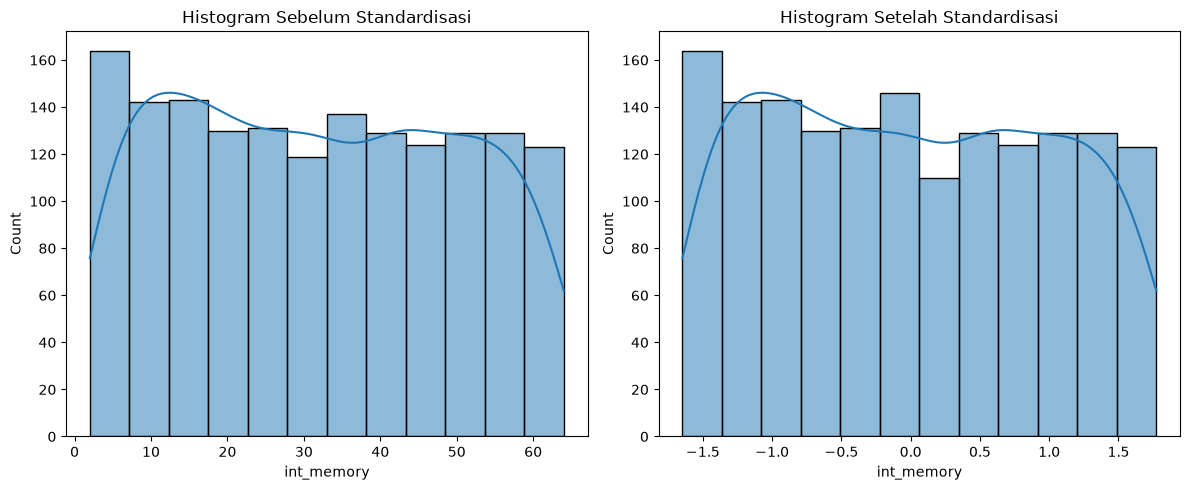

In [60]:
# Visualisasi perbandingan sebelum dan sesudah standardisasi pada data latih
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(x_train[continuous_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

plt.subplot(1, 2, 2)
sns.histplot(x_train_scaled[continuous_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.tight_layout()
plt.show()

* *Histogram sebelah kiri menunjukkan distribusi data sebelum standardisasi, sedangkan histogram sebelah kanan menunjukkan distribusi setelah standardisasi.*

### 14. Exploratory Data Analysis (EDA)

Exploratory Data Analysis atau EDA merupakan proses eksplorasi data untuk memahami karakteristik dataset sebelum dan selama proses pembuatan model. Pada bagian ini beberapa fitur dipilih untuk dilihat distribusinya melalui histogram. Visualisasi data dalam proses ini membantu kita melihat bagaimana penyebaran nilai pada masing-masing fitur.


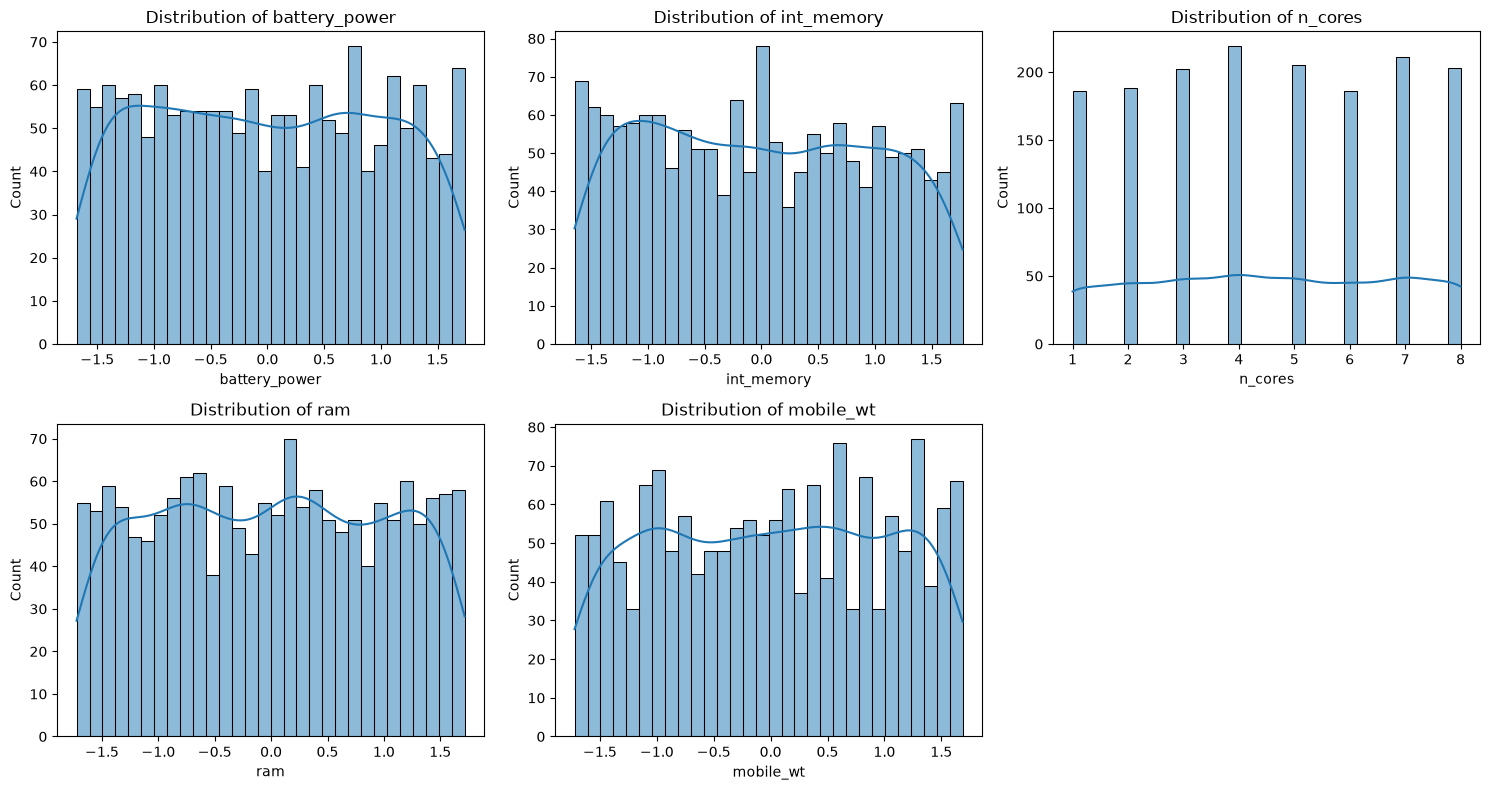

In [62]:
# EXPLORATORY DATA ANALYSIS (EDA) DATA LATIH
# Visualisasi distribusi data latih
columns_to_plot = ['battery_power', 'int_memory', 'n_cores', 'ram', 'mobile_wt']

plt.figure(figsize=(15, 8))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(x_train_scaled[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

* *Fitur yang divisualisasikan adalah battery_power, int_memory, n_cores, ram, dan mobile_wt.*


### 15. Inisialisasi, Pelatihan, dan Evaluasi Baseline Model

Pada tahap ini, kita melakukan proses utama dalam *machine learning*, yaitu membangun model baseline untuk menguji performa awal dari dua algoritma klasifikasi: **Random Forest Classifier** dan **Gradient Boosting Classifier**.

In [63]:
# Inisialisasi Model Baseline
rf_model = RandomForestClassifier(random_state=42)
gb_model = GradientBoostingClassifier(random_state=42)

# Pelatihan Model
rf_model.fit(x_train_scaled, y_train)
gb_model.fit(x_train_scaled, y_train)

# Prediksi Data Testing
y_pred_rf = rf_model.predict(x_test_scaled)
y_pred_gb = gb_model.predict(x_test_scaled)

# Evaluasi Model
print("=== Random Forest Classifier ===")
print("Akurasi:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

print("\n=== Gradient Boosting Classifier ===")
print("Akurasi:", accuracy_score(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))

=== Random Forest Classifier ===
Akurasi: 0.885
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       100
           1       0.88      0.82      0.85       100
           2       0.84      0.83      0.83       100
           3       0.92      0.91      0.91       100

    accuracy                           0.89       400
   macro avg       0.88      0.89      0.88       400
weighted avg       0.88      0.89      0.88       400


=== Gradient Boosting Classifier ===
Akurasi: 0.8925
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       100
           1       0.91      0.85      0.88       100
           2       0.81      0.87      0.84       100
           3       0.92      0.88      0.90       100

    accuracy                           0.89       400
   macro avg       0.89      0.89      0.89       400
weighted avg       0.89      0.89      0.89       400



#### Langkah-langkah Proses:
1. **Inisialisasi Model Baseline:** : Menginisialisasi objek model `RandomForestClassifier` dan `GradientBoostingClassifier` dengan parameter `random_state=42` agar hasil eksperimen dapat direproduksi (*reproducible*).

2. **Pelatihan Model (`.fit()`):**: Model dilatih menggunakan data pelatihan yang telah distandardisasi (`x_train_scaled`) beserta target jawabannya (`y_train`). Pada proses ini, algoritma belajar mengenali hubungan antara fitur-fitur spesifikasi HP dan tingkatan harganya (`price_range`).

3. **Prediksi Data Testing (`.predict()`):**: Model yang telah dilatih menguji kemampuannya dengan melakukan prediksi terhadap data pengujian (`x_test_scaled`) yang belum pernah dilihat sebelumnya.

4. **Evaluasi Model:**: Menghitung **Akurasi** (`accuracy_score`) serta menampilkan **Classification Report** (`precision`, `recall`, `f1-score`) untuk melihat seberapa tepat dan seimbang performa model dalam mengklasifikasikan setiap rentang harga HP.

### 16. Analisis Korelasi Antar Fitur

Selanjutnya dibuat correlation matrix untuk melihat hubungan antar fitur numerik. Korelasi menunjukkan seberapa kuat hubungan antara satu variabel dengan variabel lainnya. Nilai korelasi berada pada rentang -1 sampai 1. Nilai yang mendekati 1 menunjukkan hubungan positif yang kuat, sedangkan nilai yang mendekati -1 menunjukkan hubungan negatif yang kuat. Nilai yang mendekati 0 menunjukkan hubungan yang lemah.
Visualisasi dalam tahap ini digunakan sebagai bagian dari eksplorasi data sebelum proses modeling.




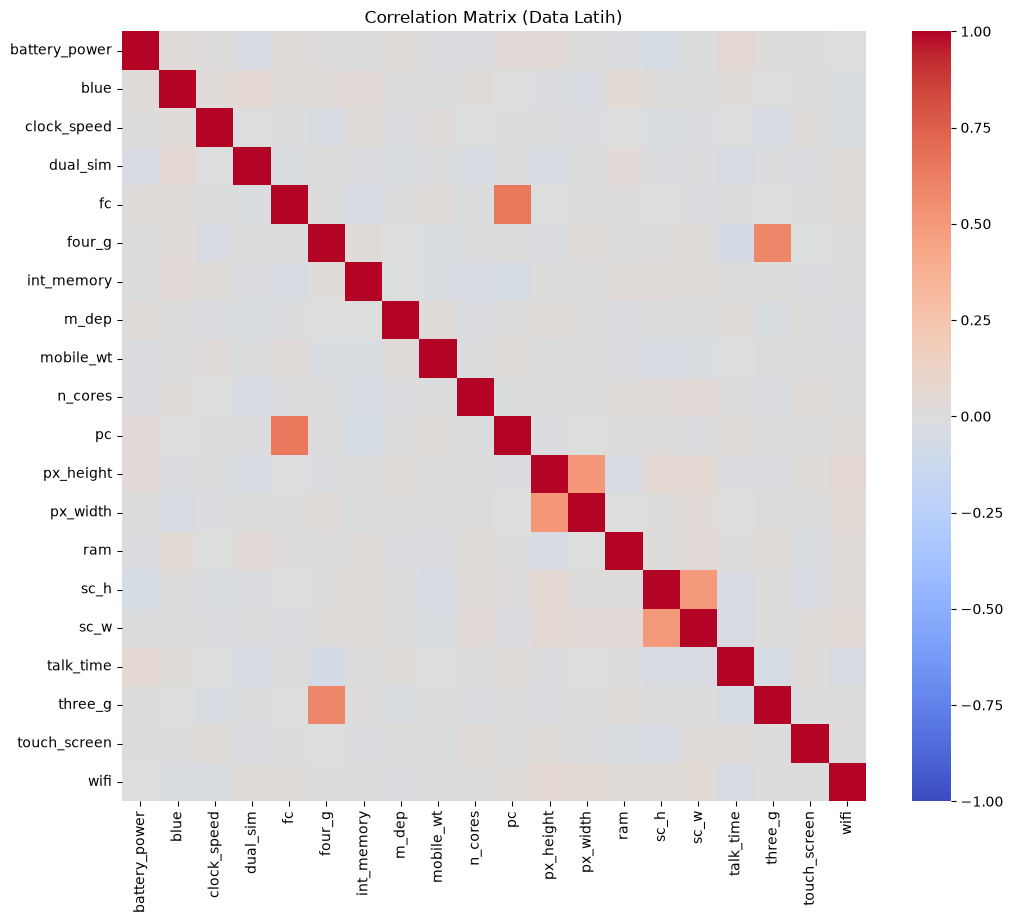

In [15]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = x_train_scaled.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix (Data Latih)')
plt.show()

16. Modeling Menggunakan Algoritma Klasifikasi

Setelah data selesai dipersiapkan, tahap berikutnya adalah modeling.

In [16]:
# MODELING (KLASIFIKASI)
# Model 1: Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(x_train_scaled, y_train)

# Model 2: Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(x_train_scaled, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

 Karena target yang ingin diprediksi adalah price_range yang terdiri dari beberapa kelas, maka masalah ini termasuk klasifikasi.
 Pada notebook ini digunakan dua algoritma sebagai pembanding, yaitu Random Forest Classifier dan Gradient Boosting Classifier.
- Random Forest bekerja dengan menggabungkan banyak decision tree untuk menghasilkan prediksi. Sedangkan, 
- Gradient Boosting membangun model secara bertahap dengan mencoba memperbaiki kesalahan dari model sebelumnya.

Kedua model dilatih menggunakan data training yang sudah melalui proses preprocessing.

17. Evaluasi Model

Setelah model selesai dilatih, model perlu diuji menggunakan data testing. Data testing tidak digunakan ketika model belajar. Oleh karena itu, data ini digunakan untuk mengetahui kemampuan model ketika menghadapi data yang belum digunakan selama proses training. Pada tahap ini Random Forest dan Gradient Boosting digunakan untuk memprediksi data testing. Kemudian hasil prediksi dibandingkan dengan nilai target sebenarnya menggunakan accuracy_score.

In [17]:
# EVALUASI MODEL
# Evaluasi Random Forest
pred_rf = rf_model.predict(x_test_scaled)
acc_rf = accuracy_score(y_test, pred_rf)

# Evaluasi Gradient Boosting
pred_gb = gb_model.predict(x_test_scaled)
acc_gb = accuracy_score(y_test, pred_gb)

18. Perbandingan Performa Model

Setelah accuracy dari kedua model diperoleh, hasilnya dibuat menjadi sebuah tabel agar lebih mudah dibandingkan.

In [18]:
# Menampilkan perbandingan performa model
df_results = pd.DataFrame({
    'Accuracy': [acc_rf, acc_gb]
}, index=['Random Forest', 'Gradient Boosting'])
display(df_results)

print("\n--- Classification Report (Random Forest) ---")
print(classification_report(y_test, pred_rf))

,Accuracy
Random Forest,0.8825
Gradient Boosting,0.8925



--- Classification Report (Random Forest) ---
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       100
           1       0.87      0.82      0.85       100
           2       0.84      0.83      0.83       100
           3       0.92      0.91      0.91       100

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



Model yang dibandingkan kali ini adalah Random Forest dan Gradient Boosting.
Selain accuracy, classification report dari Random Forest juga ditampilkan untuk memberikan informasi evaluasi yang lebih lengkap.

19. Menyiapkan Data Test Independen

Setelah model selesai dilatih dan dievaluasi, model digunakan untuk melakukan prediksi terhadap dataset test independen.
Dataset CellPhone_test.csv tidak memiliki kolom price_range, karena target tersebut memang merupakan nilai yang ingin diprediksi oleh model.

In [19]:
# PREDIKSI UNTUK DATA TEST BARU & SIMPAN MODEL
# Menyiapkan data test independen (CellPhone_test.csv)
if 'id' in Cellphone_test.columns:
    X_unseen = Cellphone_test.drop(columns=['id'])
else:
    X_unseen = Cellphone_test.copy()

X_unseen_scaled = X_unseen.copy()
X_unseen_scaled[continuous_features] = scaler.transform(X_unseen[continuous_features])

Kolom id tidak digunakan sebagai fitur karena hanya berfungsi sebagai identitas data.
Data test kemudian diproses menggunakan scaler yang sebelumnya sudah dipelajari dari data training.

## 20. Melakukan Prediksi Data Test

Pada tahap ini model Random Forest digunakan untuk memprediksi price_range dari data test independen. Model menerima data spesifikasi HP yang sudah diproses, kemudian menghasilkan kelas price_range yang diprediksi untuk setiap HP.

In [20]:
# Prediksi price_range untuk data test baru
test_predictions = rf_model.predict(X_unseen_scaled)

## 21. Evaluasi Model Menggunakan Accuracy, MAE, dan MSE

Pada tahap ini, performa model Random Forest dan Gradient Boosting dievaluasi menggunakan beberapa metrik, yaitu Accuracy, Mean Absolute Error (MAE), dan Mean Squared Error (MSE). Accuracy digunakan untuk mengukur persentase prediksi kategori yang benar. Sementara itu, MAE mengukur rata-rata selisih absolut antara kategori prediksi dan kategori sebenarnya, sedangkan MSE mengukur rata-rata kuadrat selisih tersebut.

Karena target `price_range` berupa kategori berurutan dari 0 sampai 3, MAE dan MSE dapat digunakan sebagai informasi tambahan untuk melihat seberapa jauh kesalahan prediksi antarkategori. Namun, kedua metrik ini bukan metrik utama klasifikasi dan tidak menunjukkan kesalahan harga dalam rupiah.

*Semakin kecil nilai MAE dan MSE, semakin kecil rata-rata kesalahan jarak kategori prediksi pada data pengujian.*


In [21]:
# Evaluasi prediksi Random Forest
pred_rf = rf_model.predict(x_test_scaled)

acc_rf = accuracy_score(y_test, pred_rf)
mae_rf = mean_absolute_error(y_test, pred_rf)
mse_rf = mean_squared_error(y_test, pred_rf)


# Evaluasi prediksi Gradient Boosting
pred_gb = gb_model.predict(x_test_scaled)

acc_gb = accuracy_score(y_test, pred_gb)
mae_gb = mean_absolute_error(y_test, pred_gb)
mse_gb = mean_squared_error(y_test, pred_gb)


# Membandingkan performa kedua model
df_results = pd.DataFrame({
    'Accuracy': [acc_rf, acc_gb],
    'MAE': [mae_rf, mae_gb],
    'MSE': [mse_rf, mse_gb]
}, index=['Random Forest', 'Gradient Boosting'])

display(df_results)


# Classification report Random Forest
print("\n--- Classification Report (Random Forest) ---")
print(classification_report(y_test, pred_rf))

,Accuracy,MAE,MSE
Random Forest,0.8825,0.1175,0.1175
Gradient Boosting,0.8925,0.1075,0.1075



--- Classification Report (Random Forest) ---
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       100
           1       0.87      0.82      0.85       100
           2       0.84      0.83      0.83       100
           3       0.92      0.91      0.91       100

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



*Hasil prediksi disimpan dalam variabel test_predictions.

## 21. Menyimpan Model dan Scaler

Tahap terakhir adalah menyimpan model Random Forest dan scaler ke dalam file menggunakan library joblib.

In [22]:
# Menyimpan model dan scaler ke dalam file
joblib.dump(rf_model, 'rf_model.joblib')
joblib.dump(scaler, 'scaler.joblib')
print("\nModel dan scaler berhasil disimpan!")


Model dan scaler berhasil disimpan!


Model yang sudah dilatih tidak perlu dilatih ulang setiap kali ingin digunakan. Dengan menyimpan model, model tersebut dapat digunakan kembali untuk melakukan prediksi di kemudian hari.

Scaler juga perlu disimpan karena data baru harus diproses menggunakan aturan standardisasi yang sama seperti ketika model pertama kali dilatih.